# Multiple Linear Regression & Softmax

This week we will implement some extensions of the algorithms from the last two weeks. In particular, we will see

* how to perform linear regression with more than one input variable (MLR),
* how to implement a linear classifier with more than two classes (Softmax).

We start with MLR.

## Multiple Linear Regression

We will consider a regression problem of the form
$$
y = \langle \mathbf{w},\mathbf{x} \rangle + b
$$
where $x$ is a $n$-dimensional feature vector ($n \geq 2$) , $w$ is a $n$-dimensional weight vector and $y$ a one-dimensional target feature. Extending things to higher dimensional target variables is straightforward.

The California Housing Dataset consists of price of houses in various places in California. Alongside with the price of over 20000 houses, the dataset provides 8 features:

- `MedInc`       : median income in block group
- `HouseAge`     : median house age in block group
- `AveRooms`     : average number of rooms per household
- `AveBedrms`    : average number of bedrooms per household
- `Population`   : block group population
- `AveOccup`     : average number of household members
- `Latitude`     : block group latitude
- `Longitude`    : block group longitude

The California housing dataset can be directly downloaded from scikit-learn:

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing

dataset = fetch_california_housing()

X = dataset.data
t = dataset.target

print(X.shape)
print(t.shape)

(20640, 8)
(20640,)


There are 20640 samples with 8 input features and one output (the price). The following cell describes the dataset:

In [3]:
print(dataset.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

In [11]:
print(t)

[4.526 3.585 3.521 ... 0.923 0.847 0.894]


## Linear regression

**Q:** Apply MLR on the California data using the same `LinearRegression` method of `scikit-learn` as last time. Store the predictions in a variable `y` and the MSE in a variable `mse`. The code to plot the prediction $y$ against the true value $t$ for each sample is provided. Does it work well?

MSE: 0.5243209861846072


Text(0, 0.5, 'y')

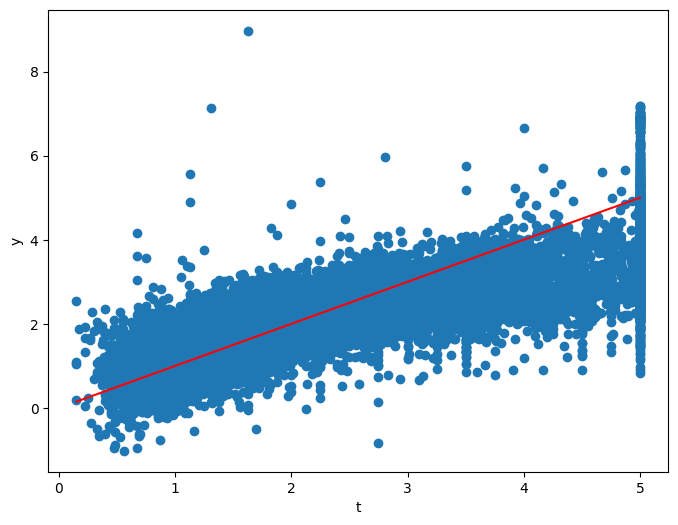

In [9]:
# @title
from sklearn.linear_model import LinearRegression

# Linear regression
reg = LinearRegression()
reg.fit(X, t)

# Prediction
y = reg.predict(X)

# mse
mse = np.mean((t - y)**2)
print("MSE:", mse)

plt.figure(figsize=(8, 6))
plt.scatter(t, y)
plt.plot([t.min(), t.max()], [t.min(), t.max()], c="red")
plt.xlabel("t")
plt.ylabel("y")

Also look at the plots of how the predictions predict the price for each feature and the plot of the weights of the model (`reg.coef_`). The code is already provided. Conclude on the relative importance of the different features: which feature has the stronger weight and why?

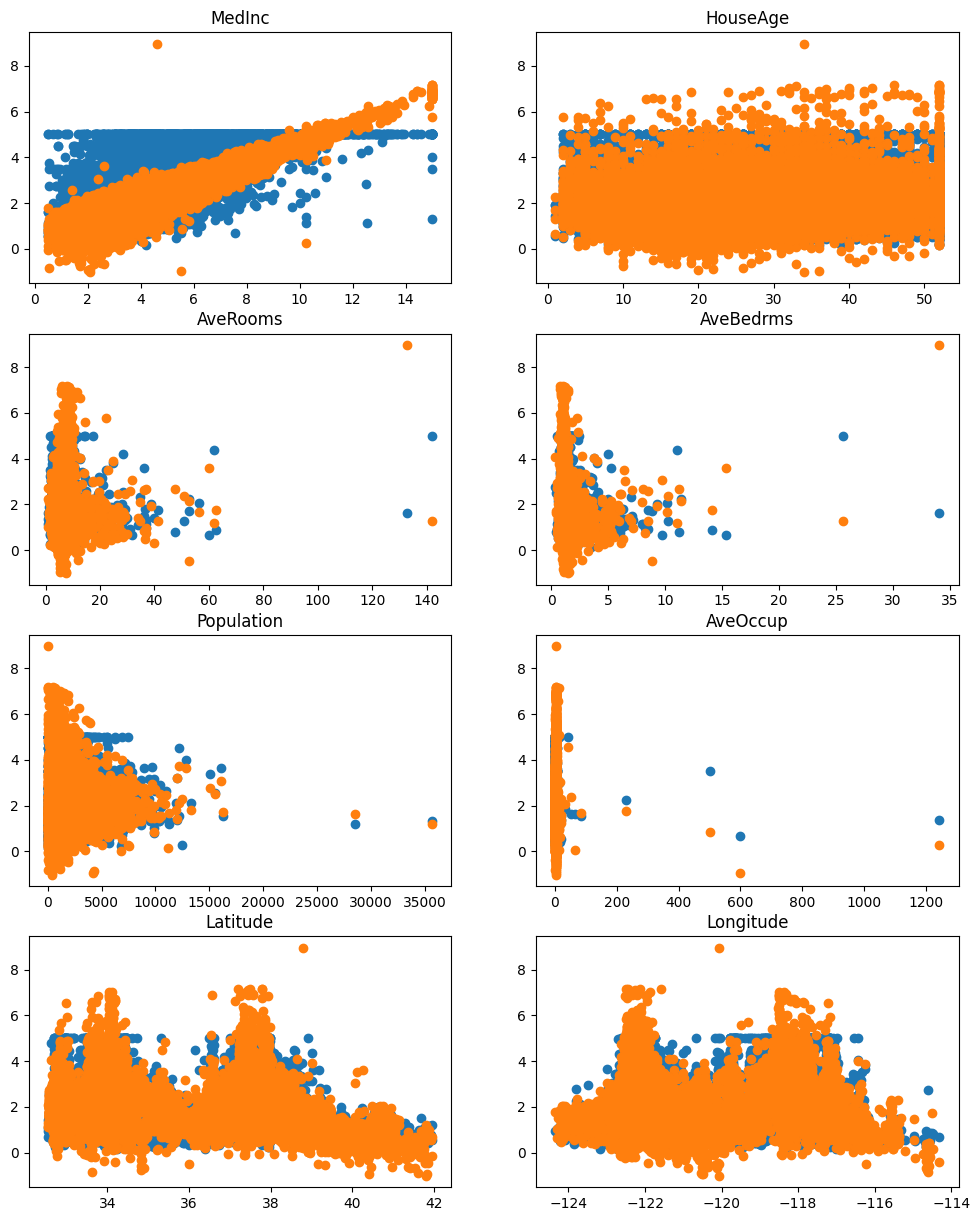

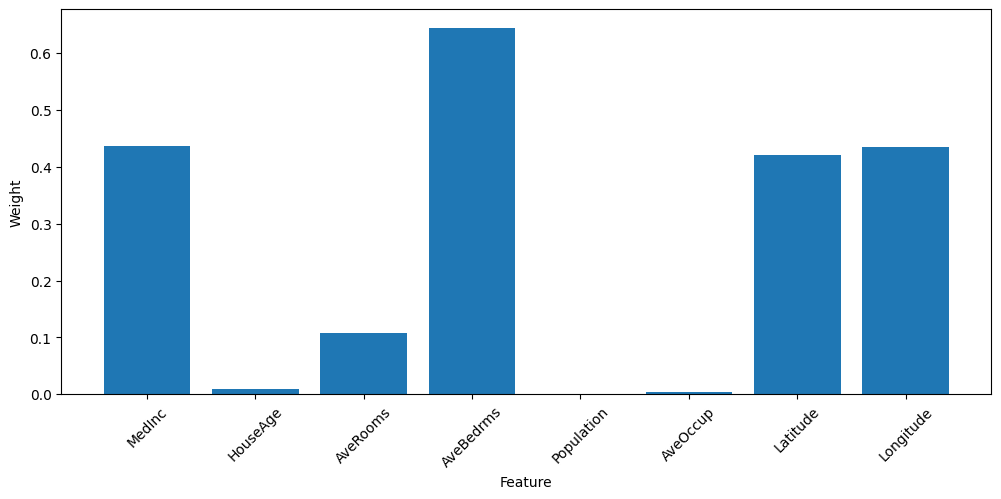

In [12]:
plt.figure(figsize=(12, 15))
for i in range(8):
    plt.subplot(4, 2 , i+1)
    plt.scatter(X[:, i], t)
    plt.scatter(X[:, i], y)
    plt.title(dataset.feature_names[i])
plt.show()

plt.figure(figsize=(12, 5))
plt.bar(range(0,len(reg.coef_)),np.abs(reg.coef_))
plt.xlabel("Feature")
plt.ylabel("Weight")
plt.xticks(range(0,len(reg.coef_)), dataset.feature_names, rotation=45)
plt.show()

A good practice in machine learning is to **normalize** the inputs, i.e. to make sure that the features have a mean of 0 and a standard deviation of 1. The formula is:

$$X^\text{normalized} = \dfrac{X - \mathbb{E}[X]}{\text{std}(X)}$$

i.e. you compute the mean and standard deviation of each column of `X` and apply the formula on each column.

**Q:** Normalize the dataset. Make sure that the new mean and std is correct.

*Tip:* `X.mean(axis=0)` and `X.std(axis=0)` should be useful.

In [13]:
# TODO: compute X_normalized
X_normalized= (X - X.mean(axis=0)) / X.std(axis=0)
print("Old mean:", X.mean(axis=0))
print("New mean:", X_normalized.mean(axis=0))
print("Old std:", X.std(axis=0))
print("New std:", X_normalized.std(axis=0))

Old mean: [ 3.87067100e+00  2.86394864e+01  5.42899974e+00  1.09667515e+00
  1.42547674e+03  3.07065516e+00  3.56318614e+01 -1.19569704e+02]
New mean: [ 5.50808322e-17  4.40646658e-17  7.71131651e-17 -1.00522519e-16
 -1.10161664e-17  0.00000000e+00  2.24729795e-15 -8.60362599e-15]
Old std: [1.89977569e+00 1.25852527e+01 2.47411320e+00 4.73899376e-01
 1.13243469e+03 1.03857980e+01 2.13590065e+00 2.00348319e+00]
New std: [1. 1. 1. 1. 1. 1. 1. 1.]


**Q:** Apply MLR again on $X^\text{normalized}$ (call the new model `reg_normalized`) and print the MSE. The provided code then plots the weights of both models side by side. What has changed?

mse: 0.5243209861846072


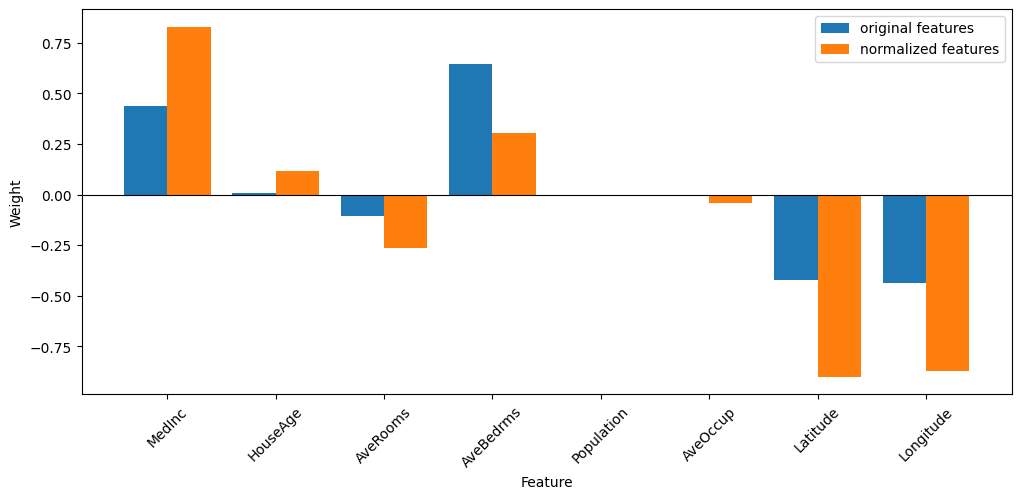

In [16]:
# TODO: fit a LinearRegression model reg_normalized on X_normalized, store the predictions in y and the MSE in mse
# Linear regression
reg_normalized = LinearRegression()
reg_normalized.fit(X_normalized, t)

# Prediction
y = reg_normalized.predict(X_normalized)

# mse
mse = np.mean((t - y)**2)
print("mse:", mse)

# Weights of both models side by side
features = np.arange(len(dataset.feature_names))
plt.figure(figsize=(12, 5))
plt.bar(features - 0.2, reg.coef_, width=0.4, label="original features")
plt.bar(features + 0.2, reg_normalized.coef_, width=0.4, label="normalized features")
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Feature")
plt.ylabel("Weight")
plt.xticks(features, dataset.feature_names, rotation=45)
plt.legend()
plt.show()

# Softmax classification

Next, we will implement a softmax classifier to handle multiclass classification.

## Loading the data

Let's now import the `digits` dataset provided by `scikit-learn`:

<https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html>

It contains 1797 small (8x8) black and white images of digits between 0 and 9.

The two following cells load the data and visualize 16 images chosen randomly.

In [17]:
from sklearn.datasets import load_digits
digits = load_digits()

N, w, h = digits.images.shape
d = w * h # number of pixels
c = len(digits.target_names) # number of classes

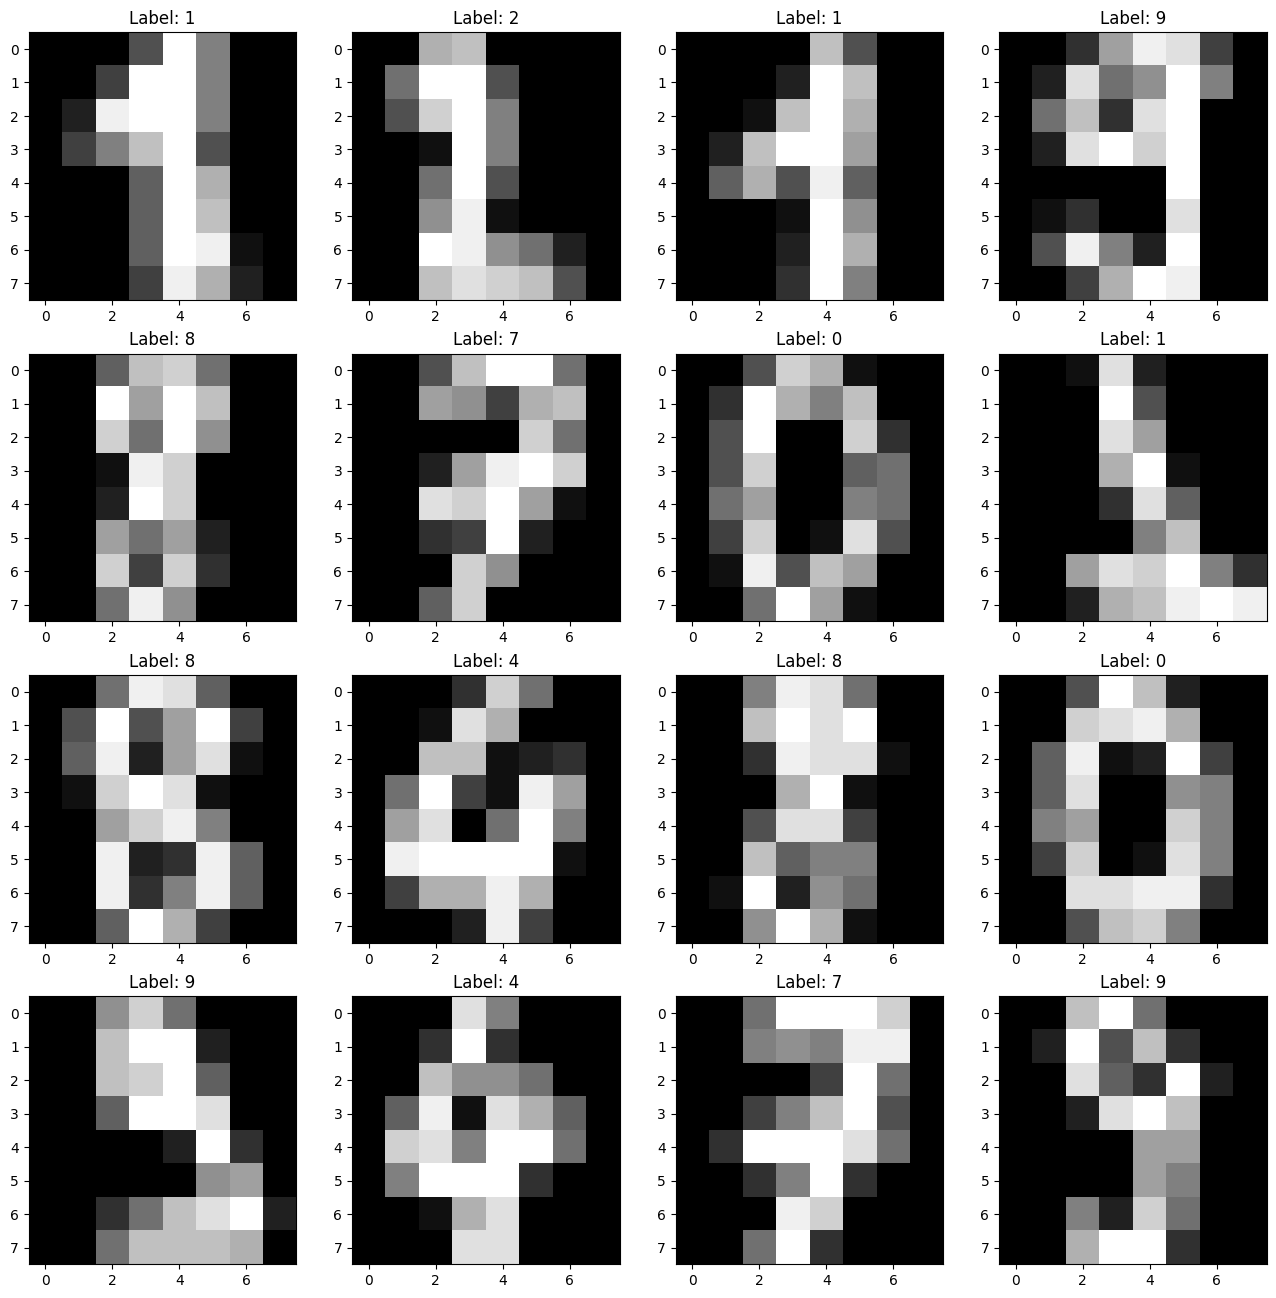

In [18]:
rng = np.random.default_rng()
indices = rng.choice(N, 16)
plt.figure(figsize=(16, 16))
for i in range(16):
    plt.subplot(4, 4, i+1)
    plt.imshow(digits.images[indices[i], :], cmap="gray")
    plt.title("Label: "+ str(digits.target[indices[i]]))
plt.show()

Digits are indeed to be recognized, the hope being that they are linearly separable and we can apply a softmax classifier directly on the pixels.

The only problem is that each image is a 8x8 matrix, while we want vectors for our model. Fortunately, that is very easy with `reshape`:

In [19]:
X = digits.images.reshape((N, d))
print(X.shape)

(1797, 64)


Let's now have a look at the targets, i.e. the ground truth / labels of each digit:

In [20]:
labels = digits.target
print(labels)
print(labels.shape)

[0 1 2 ... 8 9 8]
(1797,)


Each label is an integer between 0 and 9, while our softmax classifier expects a **one-hot-encoded** vector of 10 classes, with only one non-zero element, for example for digit 3:

$$[0, 0, 0, 1, 0, 0, 0, 0, 0, 0]$$

To do the conversion, we can use a built-in method of `scikit-learn`:

In [21]:
from sklearn.preprocessing import OneHotEncoder

t = OneHotEncoder().fit_transform(labels.reshape(-1, 1)).toarray()

print(t)
print(t.shape)

[[1. 0. 0. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]
 [0. 0. 1. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 1. 0.]
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 1. 0.]]
(1797, 10)


We split the data into a training set `X_train, t_train` and a test set `X_test, t_test` with a ratio 70/30, so called **holdout validation**. Fixing `random_state` makes everybody get the same split, and therefore the same results:

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, t_train, t_test = train_test_split(X, t, test_size=0.3, random_state=3)

N_train = X_train.shape[0]
N_test = X_test.shape[0]

print(N_train, "training samples,", N_test, "test samples.")

1257 training samples, 540 test samples.


## Softmax linear classifier

Let's remember the structure of the softmax linear classifier: the input vector $\mathbf{x}$ is transformed into a **logit score** vector $\mathbf{z}$ using a weight matrix $W$ and a bias vector $\mathbf{b}$:

$$
    \mathbf{z} = W \times \mathbf{x} + \mathbf{b}
$$

This logit score has one element per class, so the weight matrix must have a size $(c, d)$, where $c$ is the number of classes (10) and $d$ is the number of dimensions of the input space (64). The bias vector has 10 elements (one per class).

The logit score is turned into probabilities using the **softmax** operator:

$$
    y_j = P(\text{class = j}) = \frac{\exp(z_j)}{\sum_k \exp(z_k)}
$$

The following Python function allows to turn any vector $\mathbf{z}$ (numpy array) into softmax probabilities:

In [23]:
def softmax(z):
    e = np.exp(z - z.max())
    return e/np.sum(e)

**Q:** The following cell applies `softmax()` to a few vectors (feel free to try others). What do you observe? What happens when you add a constant to all elements of $\mathbf{z}$, or multiply them by a factor?

In [24]:
z = np.array([-1, 0, 2])

print("z      :", np.round(softmax(z), 3))
print("z + 100:", np.round(softmax(z + 100), 3))
print("10 * z :", np.round(softmax(10 * z), 3))
print("0.1 * z:", np.round(softmax(0.1 * z), 3))

z      : [0.042 0.114 0.844]
z + 100: [0.042 0.114 0.844]
10 * z : [0. 0. 1.]
0.1 * z: [0.289 0.32  0.391]


The loss function to use is the **cross-entropy** or **negative log-likelihood**, defined for a single example as:

$$
    \mathcal{l}(W, \mathbf{b}) =   - \mathbf{t} \cdot \log \mathbf{y} = - \log y_j
$$

where $\mathbf{t}$ is a one-hot encoding of the class of the example and $j$ is the index of the corresponding class.

After doing the derivations, we obtain the following learning rules for $W$ and $\mathbf{b}$ to minimize the loss function:

$$
    \Delta W = \eta \, (\mathbf{t} - \mathbf{y}) \, \mathbf{x}^T
$$

$$
    \Delta \mathbf{b} = \eta \, (\mathbf{t} - \mathbf{y})
$$

Note that because $W$ is a $(c, d)$ matrix, $\Delta W$ too. $(\mathbf{t} - \mathbf{y}) \, \mathbf{x}^T$ is therefore the **outer product** between the error vector $\mathbf{t} - \mathbf{y}$ ($c$ elements) and the input vector $\mathbf{x}$ ($d$ elements).

## Implementation

You will now modify your implementation of online logistic regression from last week. The learning rule has exactly the same form as for logistic regression: only the shapes of the variables change.

Some things to keep in mind:

* `W` must now be defined as a $(c, d)$ matrix (numpy array) and `b` as a vector with $c$ elements. Both can be initialized to 0.

* When computing the logit score $\mathbf{z} = W \times \mathbf{x} + \mathbf{b}$, remember that `W` is now a matrix, so its position will matter in the dot product `np.dot`.

* Use the `softmax()` function defined above on the whole vector instead of the logistic function to get the prediction $\mathbf{y}$.

* For $\Delta W$, you will need the **outer** product between the vectors $\mathbf{t} - \mathbf{y}$ and $\mathbf{x}$. Check the doc for `np.outer()`.

* The one-hot encoding of the class of the example $i$ is now a vector with 10 elements `t_train[i, :]`.

The function `evaluate()` below computes the error rate and the average cross-entropy loss of the model on a dataset. The predicted class is the one with the maximum probability, `y.argmax()`, and the correct class is the position of the 1 in the one-hot vector, `t.argmax()`.

In [25]:
def evaluate(W, b, X, T):
    """Error rate and average cross-entropy loss of the model (W, b) on the inputs X with one-hot targets T."""
    N = X.shape[0]
    error = 0
    loss = 0.
    for i in range(N):
        z = np.dot(W, X[i, :]) + b
        y = softmax(z)
        j = T[i, :].argmax() # index of the correct class

        # Error if the maximum probability is not the correct class
        if y.argmax() != j:
            error += 1

        # Cross-entropy -log(y_j), computed directly from z so that it stays finite even when y_j is rounded to 0
        loss -= z[j] - z.max() - np.log(np.sum(np.exp(z - z.max())))

    return error/N, loss/N

**Q:** Complete the training loop below. The learning rate and the number of epochs are fixed; the error and loss on the training and test sets are recorded at the end of each epoch and plotted by the following cell.

In [26]:
# Parameters
eta = 0.001
nb_epochs = 100

# TODO: initialize the weight matrix W and the bias vector b
# Initialize the weight matrix and bias vector
W = np.zeros((c, d))
b = np.zeros(c)

training_errors = []
training_losses = []
test_errors = []
test_losses = []

for epoch in range(nb_epochs):

    # Iterate over all training examples
    for i in range(N_train):
       # Prediction
        z = np.dot(W, X_train[i, :]) + b

        # Probability
        y = softmax(z)

        # Update the weight
        W += eta * np.outer((t_train[i, :] - y), X_train[i, :])

        # Update the bias
        b += eta * (t_train[i, :] - y)

    # Error and loss on the training and test sets at the end of the epoch
    error, loss = evaluate(W, b, X_train, t_train)
    training_errors.append(error)
    training_losses.append(loss)

    error, loss = evaluate(W, b, X_test, t_test)
    test_errors.append(error)
    test_losses.append(loss)

print("Final training error:", training_errors[-1])
print("Final training loss:", training_losses[-1])

print("Final test error:", test_errors[-1])
print("Final test loss:", test_losses[-1])

Final training error: 0.0
Final training loss: 0.006845338693095953
Final test error: 0.05
Final test loss: 0.17284887439851612


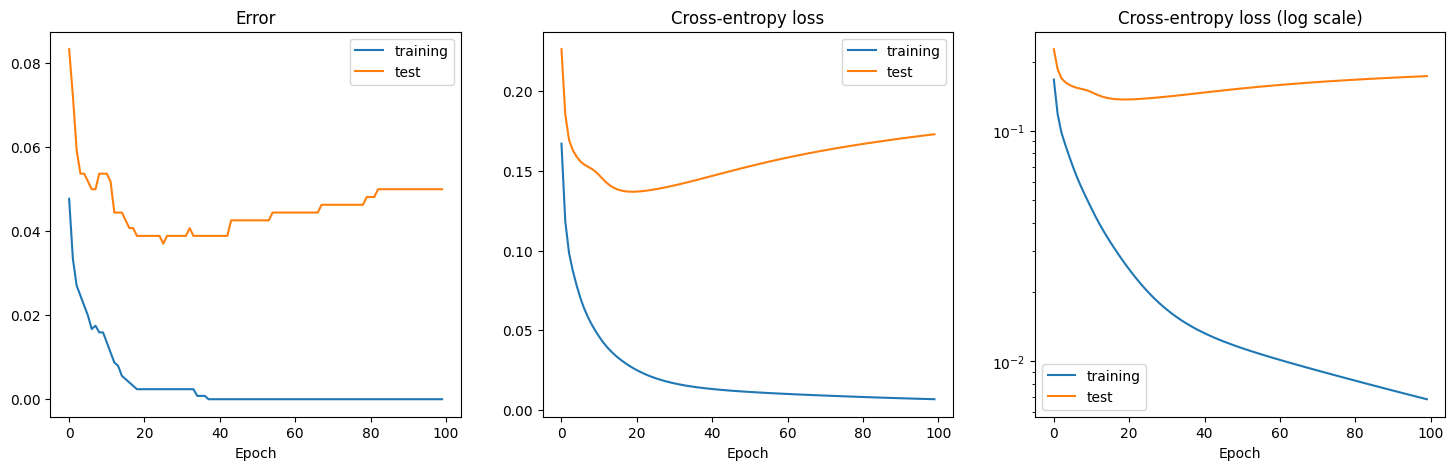

In [27]:
plt.figure(figsize=(18, 5))
plt.subplot(131)
plt.plot(training_errors, label="training")
plt.plot(test_errors, label="test")
plt.legend()
plt.xlabel("Epoch")
plt.title("Error")
plt.subplot(132)
plt.plot(training_losses, label="training")
plt.plot(test_losses, label="test")
plt.legend()
plt.xlabel("Epoch")
plt.title("Cross-entropy loss")
plt.subplot(133)
plt.plot(training_losses, label="training")
plt.plot(test_losses, label="test")
plt.yscale("log")
plt.legend()
plt.xlabel("Epoch")
plt.title("Cross-entropy loss (log scale)")
plt.show()

**Q:** What is the final training error and loss of the model? After how many epochs do you get a perfect classification on the training set? Why do the error and the loss evolve like this?

**Q:** Compare the evolution of the training and test errors and losses during training. What happens? What could you do about it?

**Q:** The following cell samples 12 misclassified images from the test and shows the predicted class together with the ground truth. What do you think?

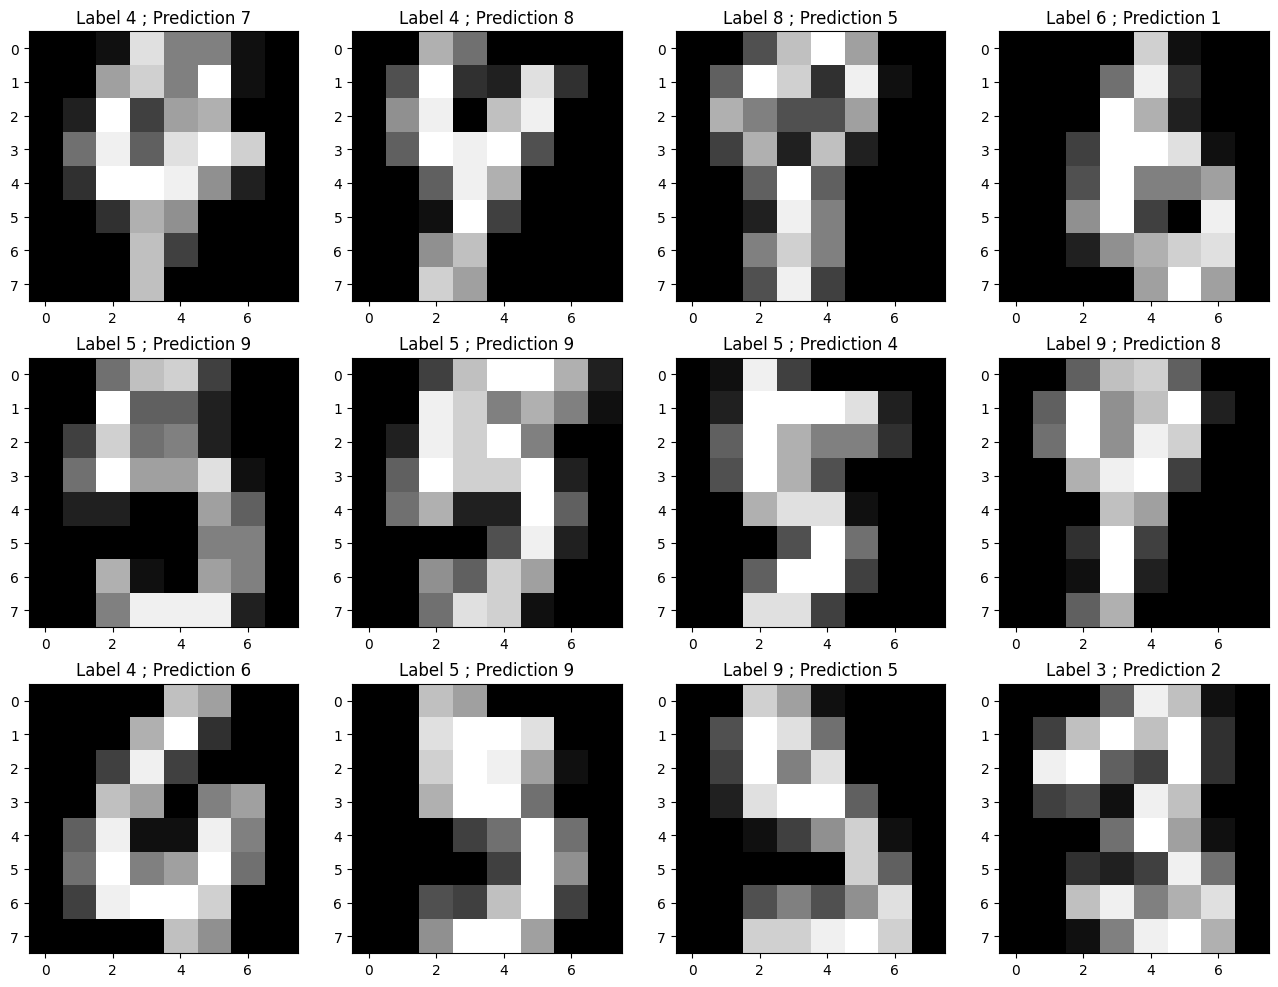

In [28]:
misclassified = []

for i in range(N_test):
    pred = softmax(np.dot(W, X_test[i, :]) + b).argmax()
    if pred != t_test[i, :].argmax():
        misclassified.append([X_test[i, :].reshape((8, 8)), t_test[i, :].argmax(), pred])
        if len(misclassified) == 12: break

plt.figure(figsize=(16, 12))
for i, (image, label, pred) in enumerate(misclassified):
    plt.subplot(3, 4, i+1)
    plt.imshow(image, cmap="gray")
    plt.title("Label " + str(label) + " ; Prediction " + str(pred))
plt.show()